In [1]:
import pandas as pd

df = pd.read_csv("../../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv")
print(df.shape)
df.dtypes

(7043, 21)


customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

In [2]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Valeurs manquantes :", df["TotalCharges"].isna().sum())
print("Ancienneté de ces clients :", df.loc[df["TotalCharges"].isna(), "tenure"].unique())

Valeurs manquantes : 11
Ancienneté de ces clients : [0]


In [3]:
df["Churn"].value_counts(normalize=True).round(3)

Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
df["ChurnFlag"] = (df["Churn"] == "Yes").astype(int)

In [5]:
df.groupby("Contract")["ChurnFlag"].agg(taux_depart="mean", nb_clients="count").round(3)

,taux_depart,nb_clients
Contract,,
Month-to-month,0.427,3875
One year,0.113,1473
Two year,0.028,1695


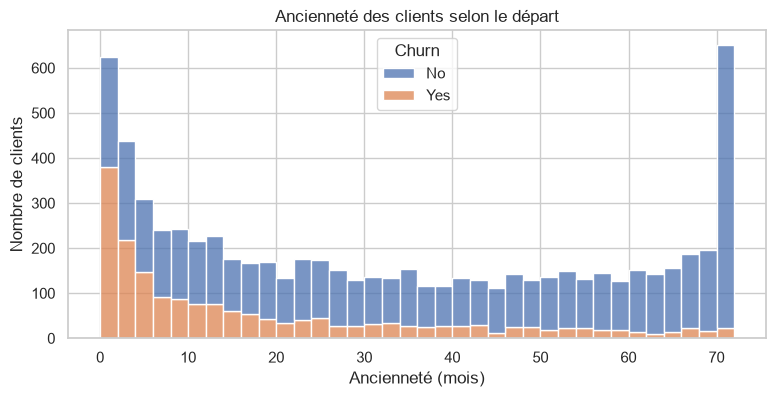

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x="tenure", hue="Churn", bins=36, multiple="stack", ax=ax)
ax.set_title("Ancienneté des clients selon le départ")
ax.set_xlabel("Ancienneté (mois)")
ax.set_ylabel("Nombre de clients")
plt.show()

In [7]:
print(df.groupby("InternetService")["ChurnFlag"].mean().round(3))
print()
print(df.groupby("Churn")["MonthlyCharges"].mean().round(2))

InternetService
DSL            0.190
Fiber optic    0.419
No             0.074
Name: ChurnFlag, dtype: float64

Churn
No     61.27
Yes    74.44
Name: MonthlyCharges, dtype: float64


In [8]:
df["tenure_group"] = pd.cut(
    df["tenure"], bins=[-1, 12, 24, 48, 72], labels=["0-12", "13-24", "25-48", "49-72"]
)
df.groupby("tenure_group", observed=True)["ChurnFlag"].agg(
    taux_depart="mean", nb_clients="count"
).round(3)

,taux_depart,nb_clients
tenure_group,,
0-12,0.474,2186
13-24,0.287,1024
25-48,0.204,1594
49-72,0.095,2239


In [9]:
df.pivot_table(
    index="tenure_group", columns="Contract", values="ChurnFlag",
    aggfunc="mean", observed=True
).round(3)

Contract,Month-to-month,One year,Two year
tenure_group,,,
0-12,0.514,0.105,0.000
13-24,0.377,0.081,0.000
25-48,0.329,0.106,0.022
49-72,0.260,0.129,0.033


## Conclusions de l'exploration

1. **Déséquilibre des classes** : environ 26,5 % des clients sont partis. Un modèle qui prédirait « personne ne part » aurait 73,5 % de précision sans rien détecter : l'*accuracy* est donc une mauvaise métrique ici.
2. **Ancienneté** : le risque de départ est maximal la première année et décroît avec l'ancienneté. Une partie de l'effet est de la sélection (les clients insatisfaits sont déjà partis).
3. **Contrat** : le départ est d'environ 43 % en mensuel contre environ 3 % à deux ans. L'écart reflète l'engagement contractuel et l'auto-sélection, pas seulement la satisfaction.
4. **Fibre optique** : taux de départ nettement plus élevé qu'en DSL. C'est une corrélation, la cause (prix, qualité, concurrence) reste à investiguer.
5. **Qualité des données** : `TotalCharges` est vide pour 11 clients dont l'ancienneté est de 0 mois (nouveaux clients, rien encore facturé). Ce sont des valeurs absentes légitimes, pas des erreurs.

**Piste métier** : concentrer les actions de rétention sur la première année, en particulier pour les contrats mensuels.
